## BiciLogic - First real map test

This notebook tests whether we can download and use a real street network from OpenStreetMap using OSMnx.

In [1]:
import osmnx as ox
import networkx as nx

place_name = "Ixelles, Brussels, Belgium"

G = ox.graph_from_place(
    place_name,
    network_type="bike",
    simplify=True
)

print(G)

MultiDiGraph with 1111 nodes and 2439 edges


In [2]:
#fig, ax = ox.plot_graph(G, node_size=5, edge_linewidth=0.8)

In [3]:
edges = ox.graph_to_gdfs(G, nodes=False)
nodes = ox.graph_to_gdfs(G, edges=False)
display(nodes.head())
display(edges.head())

,y,x,street_count,highway,railway,geometry
osmid,,,,,,
8092115,50.820505,4.385124,4,NaN,NaN,POINT (4.38512 50.82051)
8092118,50.815627,4.389711,3,NaN,NaN,POINT (4.38971 50.81563)
8092119,50.815584,4.390041,3,NaN,NaN,POINT (4.39004 50.81558)
8092121,50.815763,4.390083,3,NaN,NaN,POINT (4.39008 50.81576)
8092123,50.813790,4.384229,4,NaN,NaN,POINT (4.38423 50.81379)


osmid      highway maxspeed  \
u       v           key                                    
8092115 5936520921  0      4309691  residential       30   
        26024164    0      4309694     tertiary       30   
        10288457945 0    690893940      primary       50   
8092118 26083662    0      4306850     tertiary       30   
        8092119     0    258798211     tertiary       30   

                                                                     name  \
u       v           key                                                     
8092115 5936520921  0               Avenue des Saisons - Jaargetijdenlaan   
        26024164    0    Boulevard Général Jacques - Generaal Jacqueslaan   
        10288457945 0    Boulevard Général Jacques - Generaal Jacqueslaan   
8092118 26083662    0             Avenue de l'Université - Hogeschoollaan   
        8092119     0                   Avenue de la Couronne - Kroonlaan   

                         oneway reversed      length lanes  \
u       v           key                                      
8092115 5936520921  0     False    False    4.414304   NaN   
        26024164    0     False     True   20.609518     2   
        10288457945 0      True    False  110.687507     2   
8092118 26083662    0     False    False   88.270858   NaN   
        8092119     0      True    False   27.083028   NaN   

                                                                  geometry  \
u       v           key                                                      
8092115 5936520921  0      LINESTRING (4.38512 50.82051, 4.38516 50.82047)   
        26024164    0    LINESTRING (4.38512 50.82051, 4.38506 50.82057...   
        10288457945 0    LINESTRING (4.38512 50.82051, 4.38526 50.82055...   
8092118 26083662    0    LINESTRING (4.38971 50.81563, 4.38966 50.81561...   
        8092119     0    LINESTRING (4.38971 50.81563, 4.38974 50.8156,...   

                         ref    junction width service tunnel access bridge  
u       v           key                                                      
8092115 5936520921  0    NaN         NaN   NaN     NaN    NaN    NaN    NaN  
        26024164    0    NaN         NaN   NaN     NaN    NaN    NaN    NaN  
        10288457945 0    R21         NaN   NaN     NaN    NaN    NaN    NaN  
8092118 26083662    0    NaN         NaN   NaN     NaN    NaN    NaN    NaN  
        8092119     0    NaN  roundabout   NaN     NaN    NaN    NaN    NaN

In [5]:
import networkx as nx

origin_point = (50.8205, 4.3851)        # (latitude, longitude)
destination_point = (50.8335, 4.3668)   # (latitude, longitude)

origin_node = ox.nearest_nodes(G, X=origin_point[1], Y=origin_point[0])
destination_node = ox.nearest_nodes(G, X=destination_point[1], Y=destination_point[0])

route = ox.shortest_path(G, origin_node, destination_node, weight="length")

route_length = nx.path_weight(G, route, weight="length")

print("Origin node:", origin_node)
print("Destination node:", destination_node)
print("Route length in meters:", round(route_length, 1))
print("Route length in km:", round(route_length / 1000, 2))

Origin node: 8092115
Destination node: 9018479905
Route length in meters: 2161.3
Route length in km: 2.16


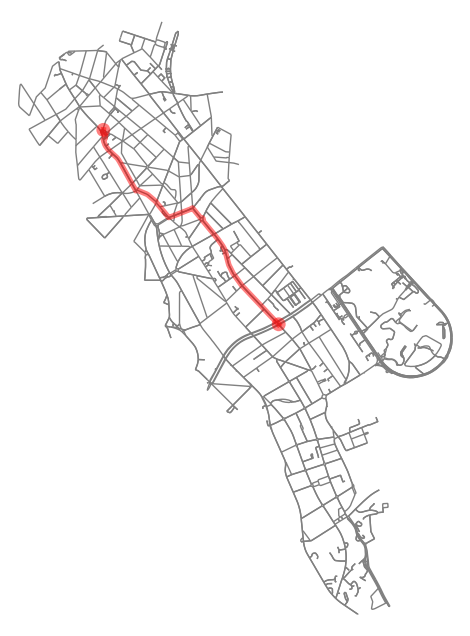

In [6]:
fig, ax = ox.plot_graph_route(
    G,
    route,
    route_linewidth=4,
    node_size=0,
    bgcolor="white",
    edge_color="gray",
    route_color="red"
)

## First result

We successfully downloaded a real bicycle street network for Ixelles using OSMnx and computed a shortest path between two geographic points.

The route length is approximately 2.16 km using the street-network distance, not straight-line distance.